# **Stacking Regressor on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**Stacking:** like voting, but smarter.
- **Voting** = simple average of the models (every model has the same say).
- **Stacking** = a second model (the **meta model**) *learns* how much to trust each base model.

How it works:
1. Base models (level 0) make predictions with cross-validation (each prediction is made by a model that did not see that row).
2. These predictions become the **input features** of the meta model (level 1).
3. The meta model learns the best way to combine them into the final prediction.

In this notebook:
- 6 base models with the **best parameters found earlier**
- We compare 4 different **meta models** using CV and pick the best
- We look at the weights the meta model gives to each base model

### Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, StackingRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV (outer CV, used to compare the stackers)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### Base Models (level 0, best parameters from the earlier notebooks)

In [3]:
base_models = [
    ('Poly+Lasso', Pipeline([('poly', PolynomialFeatures(degree=3, include_bias=False)),
                             ('scaler', StandardScaler()),
                             ('model', Lasso(alpha=0.0316, max_iter=50000))])),

    ('SVR', Pipeline([('scaler', StandardScaler()),
                      ('model', SVR(kernel='rbf', C=100, gamma=0.1, epsilon=3))])),

    ('KNN', Pipeline([('scaler', StandardScaler()),
                      ('model', KNeighborsRegressor(n_neighbors=4, weights='distance', p=2))])),

    ('Bagging', BaggingRegressor(n_estimators=200, random_state=42)),

    ('GradientBoosting', GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=3,
                                                   subsample=0.85, random_state=42)),

    ('LightGBM', LGBMRegressor(n_estimators=500, learning_rate=0.2, num_leaves=15, min_child_samples=10,
                               subsample=0.7, subsample_freq=1, reg_lambda=5, random_state=42,
                               n_jobs=1, verbose=-1)),
]

### Meta Models (level 1) to compare
Simple meta models work best for stacking (the inputs are only 6 predictions, so a complex meta model overfits).
- `positive=True` means the weights cannot be negative (every base model is only added, never subtracted).

In [4]:
meta_models = {
    'LinearRegression (positive)': LinearRegression(positive=True),
    'Ridge':                       Ridge(alpha=1.0),
    'Lasso (positive)':            Lasso(alpha=0.01, positive=True),
    'GradientBoosting (small)':    GradientBoostingRegressor(n_estimators=100, max_depth=2,
                                                             learning_rate=0.05, random_state=42),
}

def make_stack(meta):
    # inner CV: how the base models create predictions for the meta model
    inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    return StackingRegressor(estimators=base_models, final_estimator=clone(meta), cv=inner_cv, n_jobs=-1)

### Compare meta models with CV
The whole stack (base models + meta model) is evaluated with the 5-fold CV on the training data.

In [5]:
%%time
rows = []
for name, meta in meta_models.items():
    scores = cross_val_score(make_stack(meta), x_train, y_train, cv=cv, scoring='r2')
    rows.append({'Meta Model': name, 'CV_R2': scores.mean(), 'CV_R2_std': scores.std()})
    print(f'{name:<30} CV R2 = {scores.mean():.4f} (+/- {scores.std():.4f})')

meta_df = pd.DataFrame(rows).sort_values('CV_R2', ascending=False).reset_index(drop=True)
best_meta_name = meta_df.loc[0, 'Meta Model']
print('\nBest meta model:', best_meta_name)

LinearRegression (positive)    CV R2 = 0.9379 (+/- 0.0133)
Ridge                          CV R2 = 0.9373 (+/- 0.0129)
Lasso (positive)               CV R2 = 0.9379 (+/- 0.0133)
GradientBoosting (small)       CV R2 = 0.9317 (+/- 0.0124)

Best meta model: Lasso (positive)
CPU times: total: 19.2 s
Wall time: 2min 30s


### Train the best Stacking model and test it

In [6]:
stack = make_stack(meta_models[best_meta_name])
stack.fit(x_train, y_train)
y_pred = stack.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))

MAE  : 2.7834
MSE  : 21.0851
RMSE : 4.5919
R2   : 0.9213


### What did the meta model learn?
The weight of each base model (a bigger weight = the meta model trusts that model more). Only linear meta models have weights.

LightGBM            0.428
Poly+Lasso          0.245
GradientBoosting    0.221
SVR                 0.078
KNN                 0.031
Bagging             0.014
dtype: float64

Sum of weights: 1.017 | Intercept: -0.508


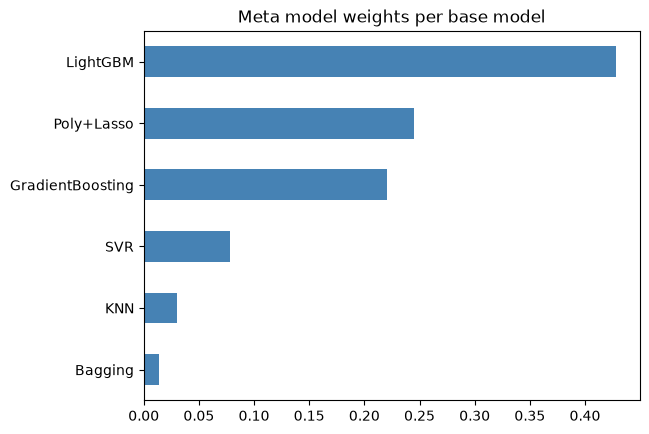

In [7]:
meta = stack.final_estimator_

if hasattr(meta, 'coef_'):
    w = pd.Series(meta.coef_, index=[n for n, _ in base_models]).sort_values(ascending=False)
    print(w.round(3))
    print('\nSum of weights:', round(w.sum(), 3), '| Intercept:', round(float(meta.intercept_), 3))
    w.sort_values().plot(kind='barh', color='steelblue', title='Meta model weights per base model')
    plt.show()
else:
    print('This meta model has no weights (it is a tree model).')

### Stacking vs each single model (test set)

In [8]:
rows = []
for name, model in base_models:
    p = clone(model).fit(x_train, y_train).predict(x_test)
    rows.append({'Model': name, 'Test_R2': r2_score(y_test, p), 'Test_MAE': mean_absolute_error(y_test, p),
                 'Test_RMSE': np.sqrt(mean_squared_error(y_test, p))})
rows.append({'Model': 'STACKING (' + best_meta_name + ')', 'Test_R2': r2, 'Test_MAE': mae, 'Test_RMSE': rmse})

compare = pd.DataFrame(rows).sort_values('Test_R2', ascending=False).reset_index(drop=True)
compare.round(4)

,Model,Test_R2,Test_MAE,Test_RMSE
0,STACKING (Lasso (positive)),0.9219,2.7743,4.5748
1,GradientBoosting,0.9139,2.9133,4.8017
2,LightGBM,0.9102,2.8889,4.9054
3,KNN,0.9006,3.6377,5.1586
4,SVR,0.8982,3.6819,5.2206
5,Bagging,0.8780,3.7147,5.7161
6,Poly+Lasso,0.8777,4.2755,5.7237


### Visualization

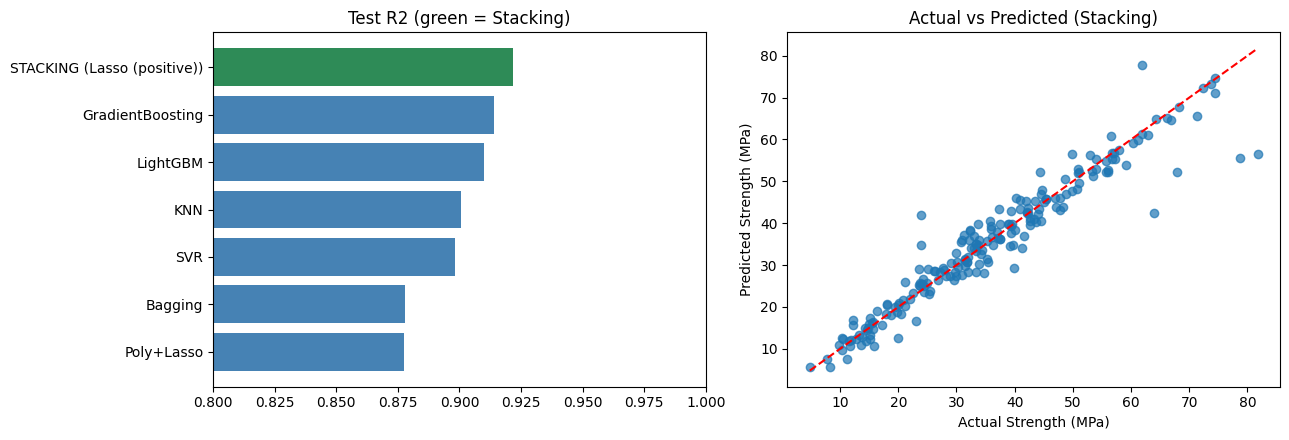

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

#Test R2: single models vs stacking
colors = ['seagreen' if m.startswith('STACKING') else 'steelblue' for m in compare['Model']]
ax[0].barh(compare['Model'].str.slice(0, 40), compare['Test_R2'], color=colors)
ax[0].invert_yaxis(); ax[0].set_xlim(0.8, 1)
ax[0].set_title('Test R2 (green = Stacking)')

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (Stacking)')

plt.tight_layout(); plt.show()

### Save the Model (.pkl)
The stacking model is trained once more on all data, then saved with `joblib`.

In [10]:
final_stack = clone(stack)
final_stack.fit(x, y)

joblib.dump(final_stack, 'stacking_concrete_model.pkl', compress=3)
meta_df.to_csv('stacking_meta_results.csv', index=False)
print('Saved: stacking_concrete_model.pkl, stacking_meta_results.csv')

Saved: stacking_concrete_model.pkl, stacking_meta_results.csv


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test R2** above (trained without the test rows).

In [11]:
model = joblib.load('stacking_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength:

 [21.69 13.82 17.52 29.95 68.06]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [12]:
try:
    from google.colab import files
    files.download('stacking_concrete_model.pkl')
    files.download('stacking_meta_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
